# Conception du Modèle CNN

In [2]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [3]:
saving_dir_path = os.path.join("..", "data", "outputs")

with (
    open(os.path.join(saving_dir_path, "X_train_images.npy"), 'rb') as f, 
    open(os.path.join(saving_dir_path, "X_test_images.npy"), 'rb') as e,
    open(os.path.join(saving_dir_path, "y_train.npy"), 'rb') as a,
    open(os.path.join(saving_dir_path, "y_test.npy"), 'rb') as b
):
    normalized_X_train = np.load(f)
    X_test = np.load(e)
    y_train = np.load(a)
    y_test = np.load(b)

In [4]:
classes_names = np.unique(y_test)
classes_names

array([0, 1, 2, 3])

In [5]:
model = tf.keras.Sequential()
# 32 filters, kernel-size = 3, ajouter des padding 0 => Features MAP
model.add(
    tf.keras.layers.Input(normalized_X_train.shape[1:])
)
model.add(
    tf.keras.layers.Conv2D(16, (3, 3), 
    activation='relu', 
    padding="same")
)
model.add(
    tf.keras.layers.Conv2D(8, (3, 3), 
    activation='relu', 
    padding="same")
)
model.add(tf.keras.layers.Flatten())

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 8)    │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 401408)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,608 (6.28 KB)

 Trainable params: 1,608 (6.28 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.add(tf.keras.layers.Dense(8, activation="relu"))
model.add(tf.keras.layers.Dense(len(classes_names), activation="softmax"))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 8)    │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 401408)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │     3,211,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,212,916 (12.26 MB)

 Trainable params: 3,212,916 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        # tf.keras.metrics.F1Score(
        #     average="macro",
        #     threshold=None
        # )
    ]
)

In [8]:
# X_train, X_val, y_train, y_val = train_test_split(
#     normalized_X_train,
#     y_train,
#     test_size=0.1,
#     random_state=42,
#     shuffle=True
# )
normalized_X_test = X_test/255
X_val = normalized_X_test[:-4]
y_val = y_test[:-4]

In [10]:
# taux d’apprentissage, nombre d’époques, taille de batch
lr = 0.001
epochs = 10
batchs = normalized_X_train.shape[0]//100

history = model.fit(
    normalized_X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batchs,
)

Epoch 1/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 33s 311ms/step - accuracy: 0.4884 - loss: 1.1955 - val_accuracy: 0.6466 - val_loss: 0.7132
Epoch 2/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 36s 274ms/step - accuracy: 0.7785 - loss: 0.5327 - val_accuracy: 0.8169 - val_loss: 0.5464
Epoch 3/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 28s 282ms/step - accuracy: 0.8930 - loss: 0.3257 - val_accuracy: 0.8770 - val_loss: 0.3609
Epoch 4/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 29s 288ms/step - accuracy: 0.9342 - loss: 0.1874 - val_accuracy: 0.8941 - val_loss: 0.3019
Epoch 5/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 29s 286ms/step - accuracy: 0.9419 - loss: 0.1455 - val_accuracy: 0.8927 - val_loss: 0.3364
Epoch 6/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 29s 282ms/step - accuracy: 0.9411 - loss: 0.1280 - val_accuracy: 0.8856 - val_loss: 0.4172
Epoch 7/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 39s 266ms/step - accuracy: 0.9791 - loss: 0.0618 - val_accuracy: 0.8927 - val_loss: 0.3844
Epoch 8/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 29s 285ms/step - accuracy: 0.9927 - loss: 0

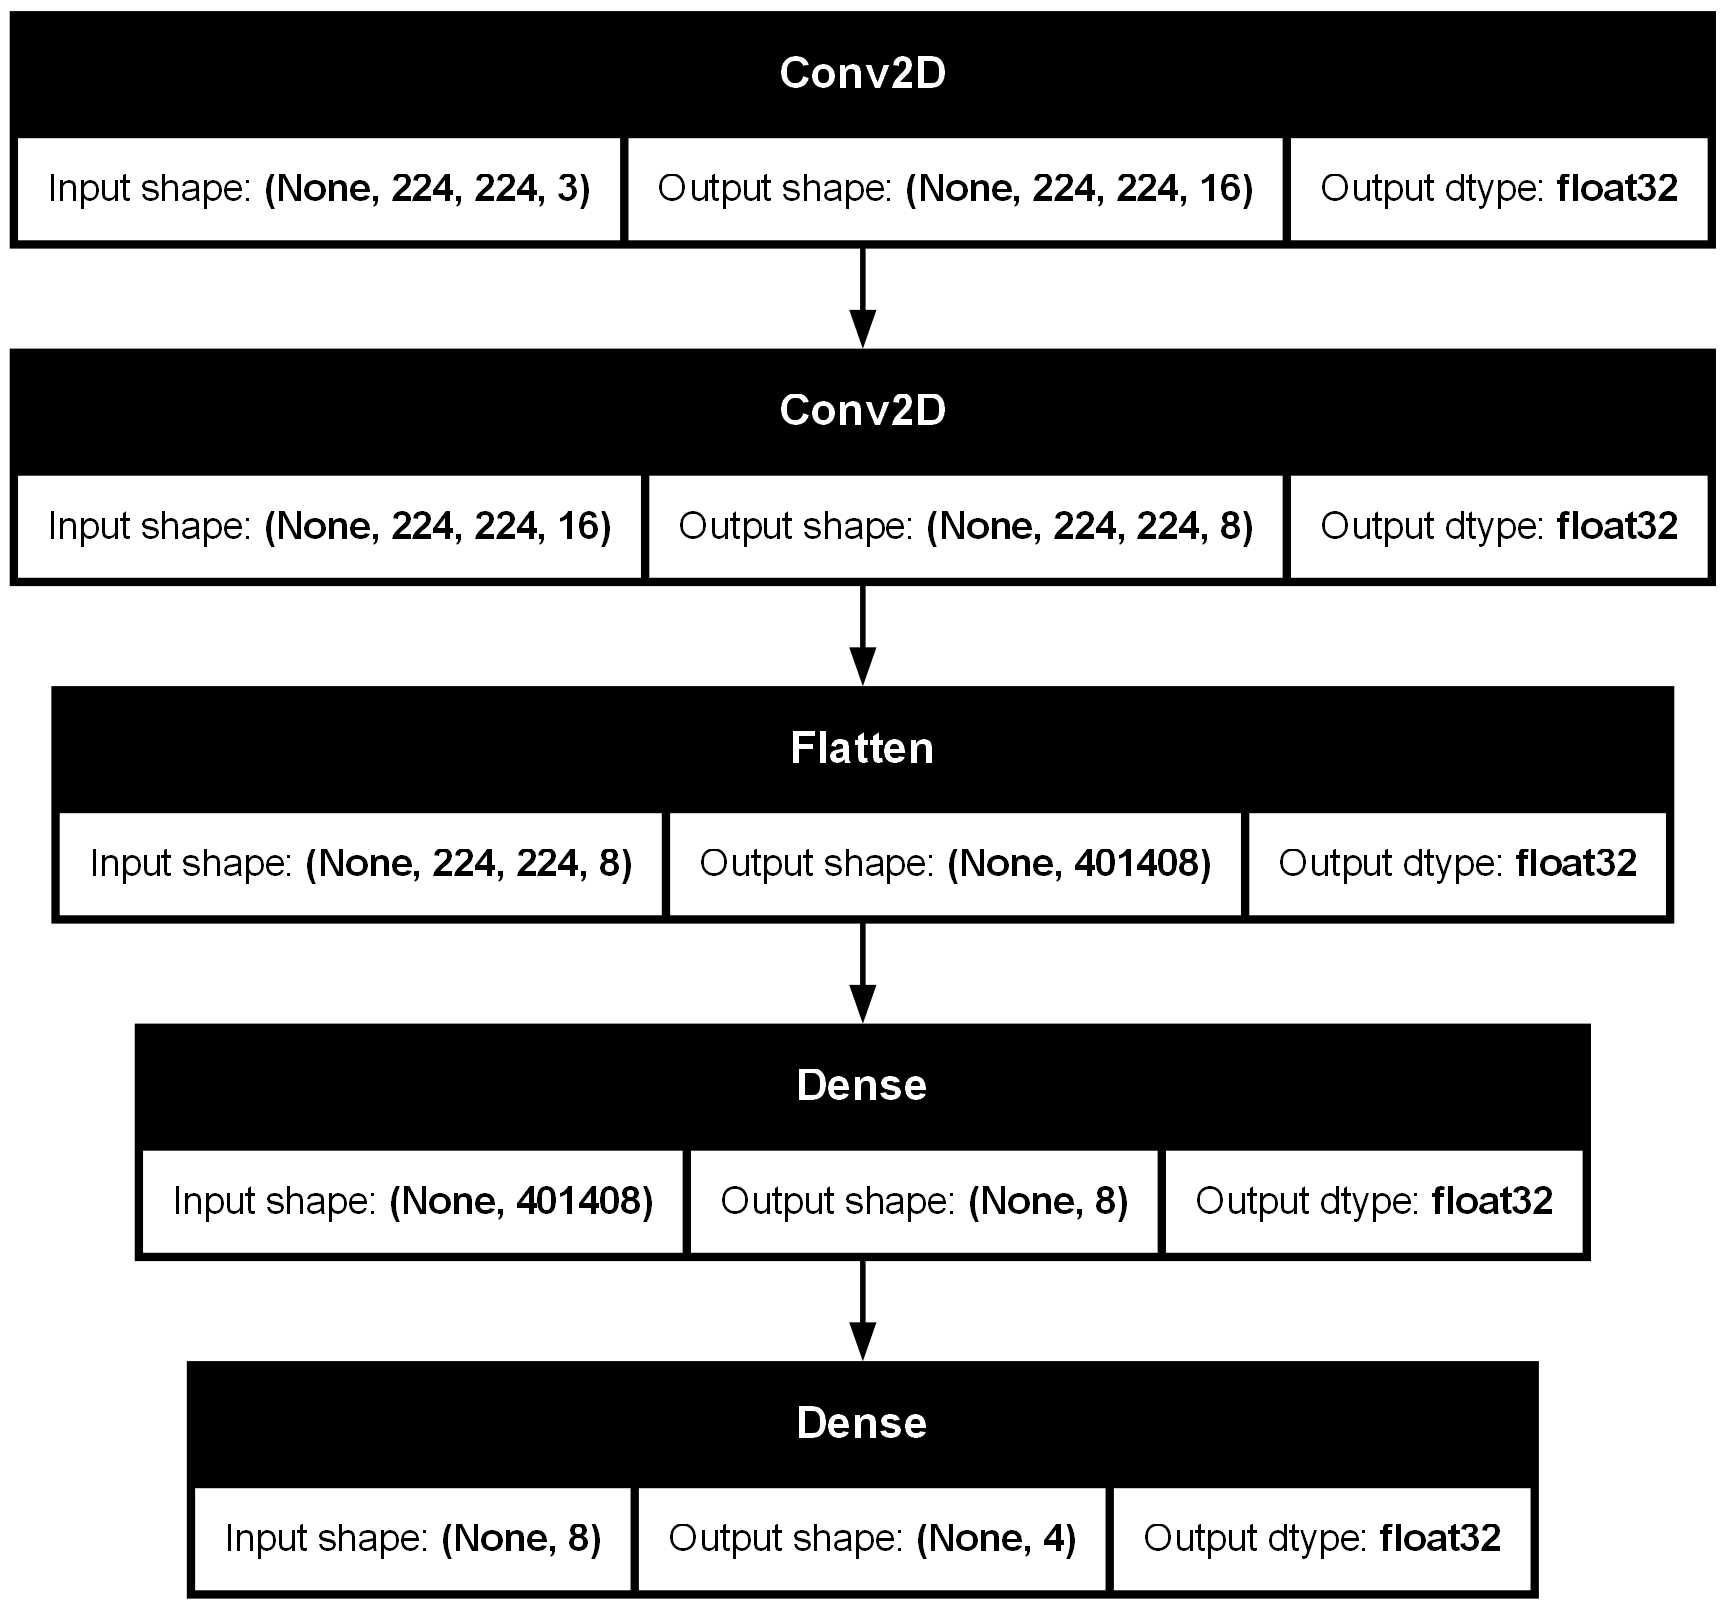

In [12]:
tf.keras.utils.plot_model(
    model, 
    to_file="../model.png", 
    show_shapes=True,
    show_dtype=True
)